# Toronto Firearm Incidents Final Project Code

This notebook analyzes the Toronto Police Service Shooting and Firearm Discharge dataset.

**Research question:**  
Do the neighbourhoods with the most firearm-related incidents also have the most harmful incidents, or does the answer change depending on how risk is measured?

The analysis uses:
- data loading and cleaning
- descriptive statistics
- neighbourhood comparison
- ranking
- harm rate per incident
- correlation
- bar charts, line charts, and scatter plot

## 1. Import libraries

These are common Python libraries for data analysis and visualization.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

## 2. Load the dataset

Download the CSV file from the Toronto Police Service Open Data page and put it in the same folder as this notebook.

Rename the file as:

`shooting_firearm_discharges.csv`

In [2]:
df = pd.read_csv("shooting_firearm_discharges.csv")

# Show the first five rows
df.head()

,OBJECTID,EVENT_UNIQUE_ID,OCC_DATE,OCC_YEAR,OCC_MONTH,OCC_DOW,OCC_DOY,OCC_DAY,OCC_HOUR,OCC_TIME_RANGE,...,INJURIES,EVENT_TYPE,HOOD_158,NEIGHBOURHOOD_158,HOOD_140,NEIGHBOURHOOD_140,LONG_WGS84,LAT_WGS84,x,y
0,1,GO-2004133803,1/1/2004 5:00:00 AM,2004,January,Thursday,1,1,0,Night,...,1,Shooting,023,Pelmo Park-Humberlea (23),023,Pelmo Park-Humberlea (23),-79.538218,43.733742,-8.854154e+06,5.424330e+06
1,2,GO-2004120070,1/3/2004 5:00:00 AM,2004,January,Saturday,3,3,1,Night,...,0,Firearm Discharge,NSA,NSA,NSA,NSA,0.000000,0.000000,6.327780e-09,5.664924e-09
2,3,GO-2004135509,1/4/2004 5:00:00 AM,2004,January,Sunday,4,4,4,Night,...,2,Shooting,078,Kensington-Chinatown (78),078,Kensington-Chinatown (78),-79.399163,43.656119,-8.838674e+06,5.412379e+06
3,4,GO-2004126451,1/5/2004 5:00:00 AM,2004,January,Monday,5,5,13,Afternoon,...,1,Shooting,124,Kennedy Park (124),124,Kennedy Park (124),-79.256039,43.732900,-8.822742e+06,5.424200e+06
4,5,GO-2004139160,1/6/2004 5:00:00 AM,2004,January,Tuesday,6,6,19,Evening,...,0,Firearm Discharge,146,Malvern East (146),132,Malvern (132),-79.207412,43.801802,-8.817329e+06,5.434822e+06


## 3. Check the dataset

This step helps us understand the structure of the dataset, including the column names, size, and data types.

In [3]:
# Check the size of the dataset
df.shape

(6829, 22)

In [4]:
# Check column names
df.columns.tolist()

['OBJECTID',
 'EVENT_UNIQUE_ID',
 'OCC_DATE',
 'OCC_YEAR',
 'OCC_MONTH',
 'OCC_DOW',
 'OCC_DOY',
 'OCC_DAY',
 'OCC_HOUR',
 'OCC_TIME_RANGE',
 'DIVISION',
 'DEATH',
 'INJURIES',
 'EVENT_TYPE',
 'HOOD_158',
 'NEIGHBOURHOOD_158',
 'HOOD_140',
 'NEIGHBOURHOOD_140',
 'LONG_WGS84',
 'LAT_WGS84',
 'x',
 'y']

In [5]:
# Check general information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6829 entries, 0 to 6828
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   OBJECTID           6829 non-null   int64  
 1   EVENT_UNIQUE_ID    6829 non-null   object 
 2   OCC_DATE           6829 non-null   object 
 3   OCC_YEAR           6829 non-null   int64  
 4   OCC_MONTH          6829 non-null   object 
 5   OCC_DOW            6829 non-null   object 
 6   OCC_DOY            6829 non-null   int64  
 7   OCC_DAY            6829 non-null   int64  
 8   OCC_HOUR           6829 non-null   int64  
 9   OCC_TIME_RANGE     6829 non-null   object 
 10  DIVISION           6829 non-null   object 
 11  DEATH              6829 non-null   int64  
 12  INJURIES           6829 non-null   int64  
 13  EVENT_TYPE         6829 non-null   object 
 14  HOOD_158           6829 non-null   object 
 15  NEIGHBOURHOOD_158  6829 non-null   object 
 16  HOOD_140           6829 

In [6]:
# Check missing values in each column
df.isnull().sum()

OBJECTID             0
EVENT_UNIQUE_ID      0
OCC_DATE             0
OCC_YEAR             0
OCC_MONTH            0
OCC_DOW              0
OCC_DOY              0
OCC_DAY              0
OCC_HOUR             0
OCC_TIME_RANGE       0
DIVISION             0
DEATH                0
INJURIES             0
EVENT_TYPE           0
HOOD_158             0
NEIGHBOURHOOD_158    0
HOOD_140             0
NEIGHBOURHOOD_140    0
LONG_WGS84           0
LAT_WGS84            0
x                    0
y                    0
dtype: int64

## 4. Select and clean the important columns

For this project, the most important variables are:
- year
- neighbourhood
- event type
- injuries
- death

The downloaded CSV uses `DEATH`, not `DEATHS`, so the code below uses `death_col = "DEATH"`.

In [7]:
# Change these column names only if your CSV file uses different names
year_col = "OCC_YEAR"
neighbourhood_col = "NEIGHBOURHOOD_158"
event_type_col = "EVENT_TYPE"
injury_col = "INJURIES"
death_col = "DEATH"

In [8]:
# Make a copy of the dataset
clean_df = df.copy()

# Convert year, injuries, and death to numeric values
clean_df[year_col] = pd.to_numeric(clean_df[year_col], errors="coerce")
clean_df[injury_col] = pd.to_numeric(clean_df[injury_col], errors="coerce")
clean_df[death_col] = pd.to_numeric(clean_df[death_col], errors="coerce")

# Replace missing injuries and death values with 0
clean_df[injury_col] = clean_df[injury_col].fillna(0)
clean_df[death_col] = clean_df[death_col].fillna(0)

# Remove rows with missing year or neighbourhood
clean_df = clean_df.dropna(subset=[year_col, neighbourhood_col])

# Remove unclear neighbourhood values if they appear in the dataset
clean_df = clean_df[clean_df[neighbourhood_col] != "NSA"]

# Create a new harm variable
clean_df["total_harm"] = clean_df[injury_col] + clean_df[death_col]

# Check cleaned data
clean_df[[year_col, neighbourhood_col, event_type_col, injury_col, death_col, "total_harm"]].head()

,OCC_YEAR,NEIGHBOURHOOD_158,EVENT_TYPE,INJURIES,DEATH,total_harm
0,2004,Pelmo Park-Humberlea (23),Shooting,1,0,1
2,2004,Kensington-Chinatown (78),Shooting,2,0,2
3,2004,Kennedy Park (124),Shooting,1,0,1
4,2004,Malvern East (146),Firearm Discharge,0,0,0
5,2004,Malvern East (146),Firearm Discharge,0,0,0


## 5. Descriptive statistics

This section gives a basic overview of the cleaned dataset.

In [9]:
# Summary statistics for injuries, death, and total harm
clean_df[[injury_col, death_col, "total_harm"]].describe()

,INJURIES,DEATH,total_harm
count,6759.000000,6759.000000,6759.000000
mean,0.460719,0.116585,0.577304
std,0.764649,0.343228,0.828016
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,1.000000,0.000000,1.000000
max,24.000000,3.000000,26.000000


In [10]:
print("Total incidents:", len(clean_df))
print("Total injuries:", clean_df[injury_col].sum())
print("Total deaths:", clean_df[death_col].sum())
print("Total harm:", clean_df["total_harm"].sum())

Total incidents: 6759
Total injuries: 3114
Total deaths: 788
Total harm: 3902


## 6. Group by neighbourhood

This section calculates the total number of incidents, injuries, deaths, and total harm for each neighbourhood.

In [11]:
neighbourhood_summary = clean_df.groupby(neighbourhood_col).agg(
    total_incidents=(neighbourhood_col, "count"),
    total_injuries=(injury_col, "sum"),
    total_deaths=(death_col, "sum"),
    total_harm=("total_harm", "sum")
).reset_index()

# Harm rate shows average harm per incident
neighbourhood_summary["harm_per_incident"] = (
    neighbourhood_summary["total_harm"] / neighbourhood_summary["total_incidents"]
)

neighbourhood_summary.head()

,NEIGHBOURHOOD_158,total_incidents,total_injuries,total_deaths,total_harm,harm_per_incident
0,Agincourt North (129),21,4,0,4,0.190476
1,Agincourt South-Malvern West (128),55,29,8,37,0.672727
2,Alderwood (20),7,3,7,10,1.428571
3,Annex (95),27,19,2,21,0.777778
4,Avondale (153),5,2,2,4,0.800000


In [12]:
# Top 10 neighbourhoods by number of incidents
top_incidents = neighbourhood_summary.sort_values("total_incidents", ascending=False).head(10)
top_incidents

,NEIGHBOURHOOD_158,total_incidents,total_injuries,total_deaths,total_harm,harm_per_incident
53,Glenfield-Jane Heights (25),347,158,23,181,0.521614
15,Black Creek (24),242,108,28,136,0.561983
95,Mount Olive-Silverstone-Jamestown (2),234,101,35,136,0.581197
139,West Humber-Clairville (1),162,86,14,100,0.617284
156,York University Heights (27),142,68,15,83,0.584507
44,Englemount-Lawrence (32),129,46,9,55,0.426357
65,Humber Summit (21),128,43,15,58,0.453125
157,Yorkdale-Glen Park (31),125,62,16,78,0.624000
143,Weston (113),119,38,17,55,0.462185
114,Regent Park (72),119,51,20,71,0.596639


In [13]:
# Top 10 neighbourhoods by total harm
top_harm = neighbourhood_summary.sort_values("total_harm", ascending=False).head(10)
top_harm

,NEIGHBOURHOOD_158,total_incidents,total_injuries,total_deaths,total_harm,harm_per_incident
53,Glenfield-Jane Heights (25),347,158,23,181,0.521614
15,Black Creek (24),242,108,28,136,0.561983
95,Mount Olive-Silverstone-Jamestown (2),234,101,35,136,0.581197
139,West Humber-Clairville (1),162,86,14,100,0.617284
137,Wellington Place (164),106,83,15,98,0.924528
156,York University Heights (27),142,68,15,83,0.584507
74,Kensington-Chinatown (78),112,70,13,83,0.741071
138,West Hill (136),103,67,13,80,0.776699
157,Yorkdale-Glen Park (31),125,62,16,78,0.624000
116,Rockcliffe-Smythe (111),118,64,8,72,0.610169


In [14]:
# Top 10 neighbourhoods by harm rate per incident
top_harm_rate = neighbourhood_summary.sort_values("harm_per_incident", ascending=False).head(10)
top_harm_rate

,NEIGHBOURHOOD_158,total_incidents,total_injuries,total_deaths,total_harm,harm_per_incident
111,Playter Estates-Danforth (67),12,19,3,22,1.833333
2,Alderwood (20),7,3,7,10,1.428571
140,West Queen West (162),14,9,5,14,1.000000
81,Lawrence Park South (103),1,1,0,1,1.000000
84,Long Branch (19),8,6,2,8,1.000000
131,The Beaches (63),8,6,2,8,1.000000
153,Yonge-Doris (151),5,5,0,5,1.000000
7,Bay-Cloverhill (169),5,3,2,5,1.000000
135,University (79),10,7,3,10,1.000000
13,Bendale-Glen Andrew (156),56,45,8,53,0.946429


## 7. Visualize the top neighbourhoods

These charts compare neighbourhoods based on incident frequency, total harm, and average harm per incident.

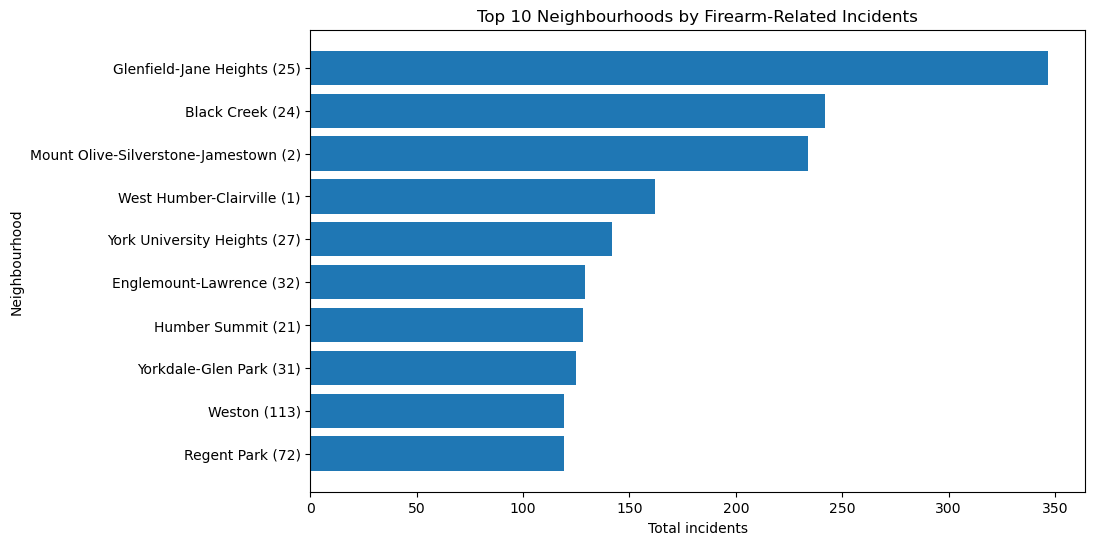

In [15]:
plt.figure(figsize=(10, 6))
plt.barh(top_incidents[neighbourhood_col], top_incidents["total_incidents"])
plt.xlabel("Total incidents")
plt.ylabel("Neighbourhood")
plt.title("Top 10 Neighbourhoods by Firearm-Related Incidents")
plt.gca().invert_yaxis()
plt.show()

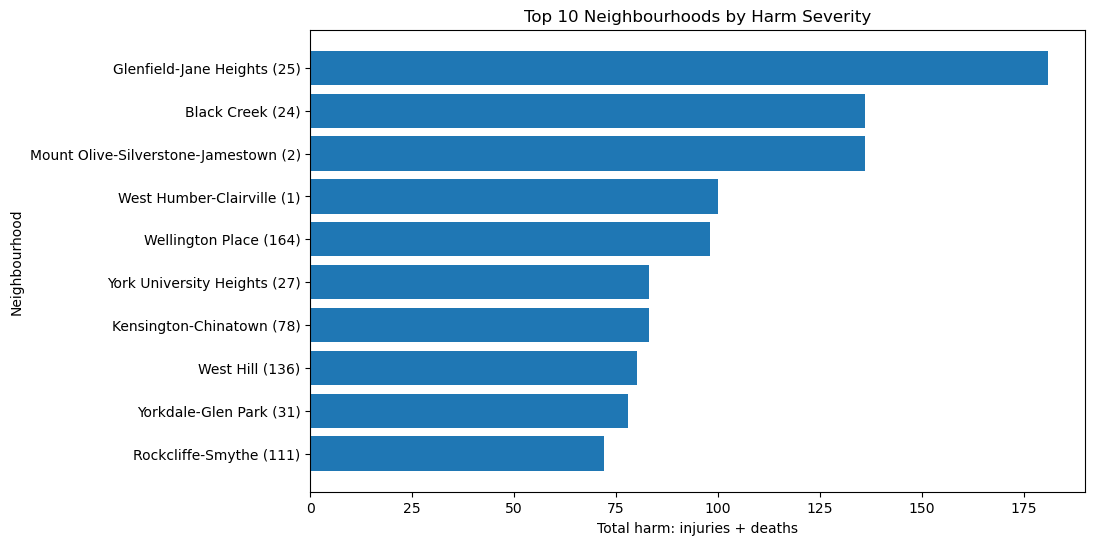

In [16]:
plt.figure(figsize=(10, 6))
plt.barh(top_harm[neighbourhood_col], top_harm["total_harm"])
plt.xlabel("Total harm: injuries + deaths")
plt.ylabel("Neighbourhood")
plt.title("Top 10 Neighbourhoods by Harm Severity")
plt.gca().invert_yaxis()
plt.show()

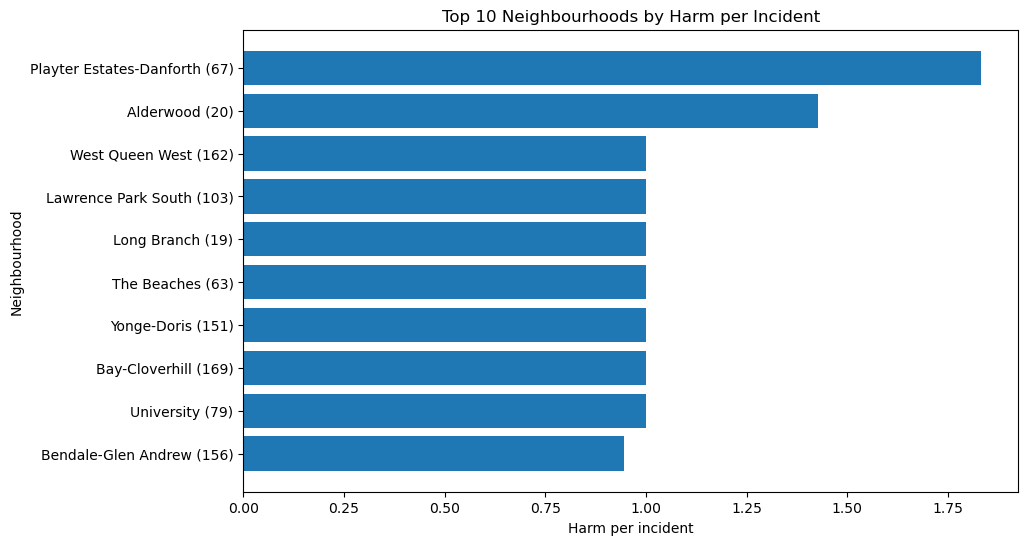

In [17]:
plt.figure(figsize=(10, 6))
plt.barh(top_harm_rate[neighbourhood_col], top_harm_rate["harm_per_incident"])
plt.xlabel("Harm per incident")
plt.ylabel("Neighbourhood")
plt.title("Top 10 Neighbourhoods by Harm per Incident")
plt.gca().invert_yaxis()
plt.show()

## 8. Compare incident frequency and harm severity

This section checks whether neighbourhoods with more incidents also tend to have more harm.

In [18]:
correlation = neighbourhood_summary["total_incidents"].corr(neighbourhood_summary["total_harm"])

print("Correlation between total incidents and total harm:", round(correlation, 3))

Correlation between total incidents and total harm: 0.968


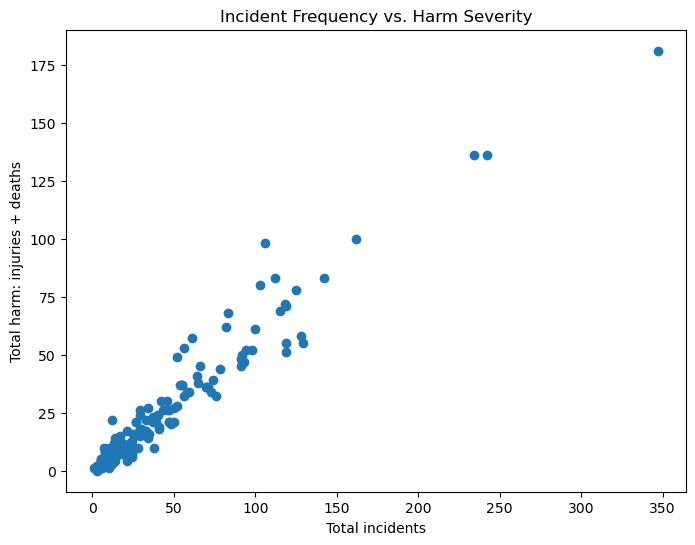

In [19]:
plt.figure(figsize=(8, 6))
plt.scatter(neighbourhood_summary["total_incidents"], neighbourhood_summary["total_harm"])
plt.xlabel("Total incidents")
plt.ylabel("Total harm: injuries + deaths")
plt.title("Incident Frequency vs. Harm Severity")
plt.show()

In [20]:
# Compare whether the same neighbourhoods appear in both Top 10 lists
top_incident_names = set(top_incidents[neighbourhood_col])
top_harm_names = set(top_harm[neighbourhood_col])

overlap = top_incident_names.intersection(top_harm_names)

print("Number of neighbourhoods appearing in both Top 10 lists:", len(overlap))
print("Neighbourhoods appearing in both lists:")
for name in overlap:
    print(name)

Number of neighbourhoods appearing in both Top 10 lists: 6
Neighbourhoods appearing in both lists:
Black Creek (24)
Glenfield-Jane Heights (25)
West Humber-Clairville (1)
Mount Olive-Silverstone-Jamestown (2)
Yorkdale-Glen Park (31)
York University Heights (27)


## 9. Rank comparison

This section creates rankings for incident frequency and harm severity.  
A large rank difference means the neighbourhood looks different depending on how risk is measured.

In [21]:
neighbourhood_summary["incident_rank"] = neighbourhood_summary["total_incidents"].rank(
    ascending=False, method="min"
)

neighbourhood_summary["harm_rank"] = neighbourhood_summary["total_harm"].rank(
    ascending=False, method="min"
)

neighbourhood_summary["harm_rate_rank"] = neighbourhood_summary["harm_per_incident"].rank(
    ascending=False, method="min"
)

neighbourhood_summary["rank_difference"] = (
    neighbourhood_summary["incident_rank"] - neighbourhood_summary["harm_rank"]
).abs()

rank_comparison = neighbourhood_summary.sort_values("rank_difference", ascending=False)

rank_comparison[
    [
        neighbourhood_col,
        "total_incidents",
        "total_harm",
        "harm_per_incident",
        "incident_rank",
        "harm_rank",
        "harm_rate_rank",
        "rank_difference"
    ]
].head(10)

,NEIGHBOURHOOD_158,total_incidents,total_harm,harm_per_incident,incident_rank,harm_rank,harm_rate_rank,rank_difference
111,Playter Estates-Danforth (67),12,22,1.833333,115.0,58.0,1.0,57.0
2,Alderwood (20),7,10,1.428571,137.0,91.0,2.0,46.0
0,Agincourt North (129),21,4,0.190476,87.0,128.0,155.0,41.0
132,Thistletown-Beaumond Heights (3),24,6,0.250000,81.0,120.0,148.0,39.0
135,University (79),10,10,1.000000,124.0,91.0,3.0,33.0
57,Harbourfront-CityPlace (165),38,10,0.263158,61.0,91.0,147.0,30.0
128,Stonegate-Queensway (16),24,7,0.291667,81.0,110.0,142.0,29.0
10,Bedford Park-Nortown (39),10,1,0.100000,124.0,152.0,157.0,28.0
21,Cabbagetown-South St.James Town (71),13,12,0.923077,112.0,84.0,14.0,28.0
140,West Queen West (162),14,14,1.000000,108.0,81.0,3.0,27.0


## 10. Trend over time

This section checks how incidents and harm change by year.

In [22]:
yearly_summary = clean_df.groupby(year_col).agg(
    total_incidents=(year_col, "count"),
    total_injuries=(injury_col, "sum"),
    total_deaths=(death_col, "sum"),
    total_harm=("total_harm", "sum")
).reset_index()

yearly_summary = yearly_summary.sort_values(year_col)

yearly_summary.head()

,OCC_YEAR,total_incidents,total_injuries,total_deaths,total_harm
0,2004,183,92,24,116
1,2005,251,171,51,222
2,2006,208,167,29,196
3,2007,202,126,44,170
4,2008,235,168,37,205


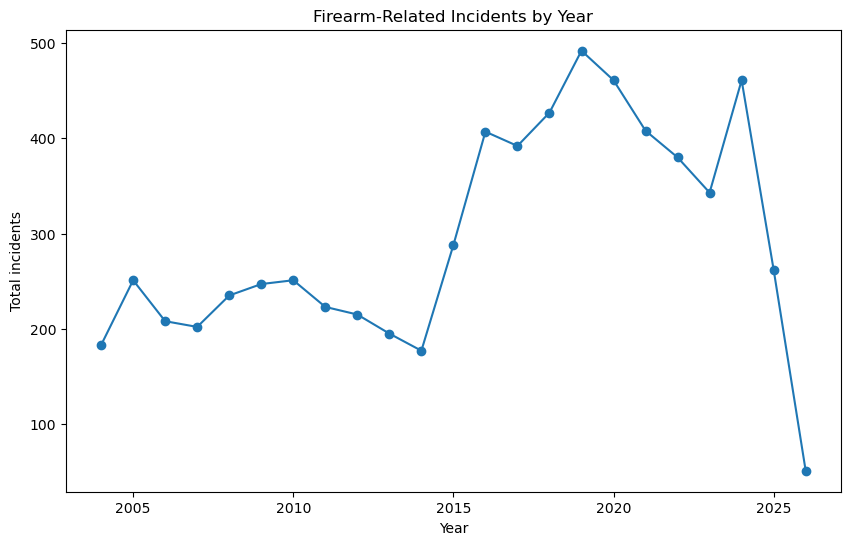

In [23]:
plt.figure(figsize=(10, 6))
plt.plot(yearly_summary[year_col], yearly_summary["total_incidents"], marker="o")
plt.xlabel("Year")
plt.ylabel("Total incidents")
plt.title("Firearm-Related Incidents by Year")
plt.show()

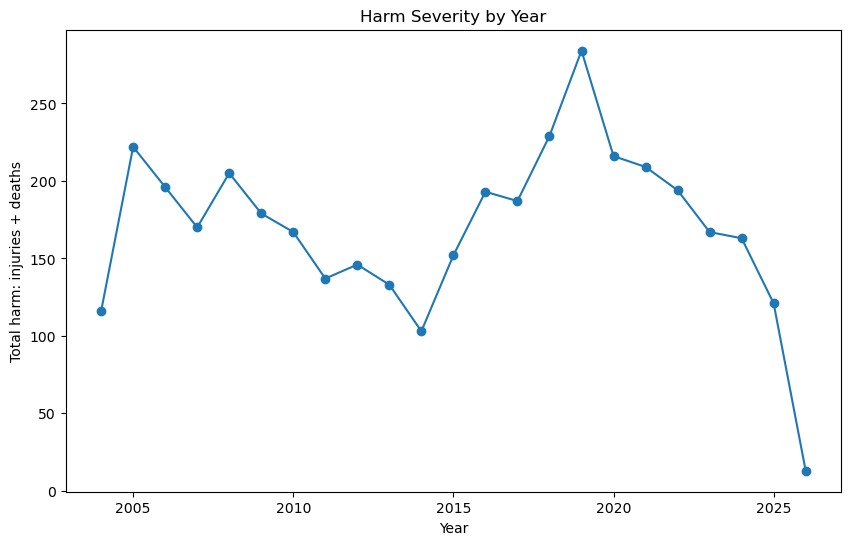

In [24]:
plt.figure(figsize=(10, 6))
plt.plot(yearly_summary[year_col], yearly_summary["total_harm"], marker="o")
plt.xlabel("Year")
plt.ylabel("Total harm: injuries + deaths")
plt.title("Harm Severity by Year")
plt.show()

## 11. Event type analysis

This section compares different event types in the dataset.

In [25]:
event_summary = clean_df.groupby(event_type_col).agg(
    total_incidents=(event_type_col, "count"),
    total_injuries=(injury_col, "sum"),
    total_deaths=(death_col, "sum"),
    total_harm=("total_harm", "sum")
).reset_index()

event_summary

,EVENT_TYPE,total_incidents,total_injuries,total_deaths,total_harm
0,Firearm Discharge,3600,0,0,0
1,Shooting,3159,3114,788,3902


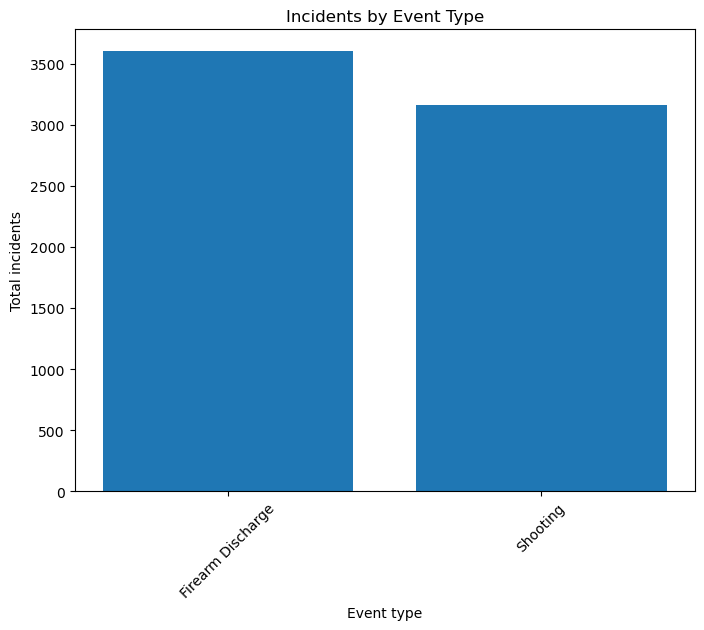

In [26]:
plt.figure(figsize=(8, 6))
plt.bar(event_summary[event_type_col], event_summary["total_incidents"])
plt.xlabel("Event type")
plt.ylabel("Total incidents")
plt.title("Incidents by Event Type")
plt.xticks(rotation=45)
plt.show()

## 12. Save result tables

These tables can be used in the report or slides.

In [27]:
neighbourhood_summary.to_csv("neighbourhood_summary.csv", index=False)
yearly_summary.to_csv("yearly_summary.csv", index=False)
event_summary.to_csv("event_summary.csv", index=False)

print("CSV result files saved.")

CSV result files saved.


## Short interpretation

After running the code, use the charts and tables to explain whether the same neighbourhoods appear as high-risk when risk is measured by total incidents and when risk is measured by total harm. If the top lists are similar, then incident frequency and harm severity show a similar pattern. If they are different, then the meaning of “high-risk neighbourhood” changes depending on the measurement.

The harm-per-incident result adds another layer to the analysis. Some neighbourhoods may not have the highest number of incidents overall, but each incident may be more harmful on average. This supports the main research question because it shows that public safety risk can look different depending on how it is measured.